# 03.4 — XAI: Explicabilidade Global + DCA
**Depende de:** 03.3 executado antes (artefatos em out/artifacts/)
**Salva em:** out/artifacts/ e out/03.4_xai/

In [1]:
from __future__ import annotations

import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "en"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        "shap_summary_fmt":    "SHAP Summary — {nome}",
        # (LIME / Permutation / ALE adicionados abaixo — mesmas chaves que 'en')
        "shap_summary_n_fmt":  "SHAP Summary — {nome} (n={n})",
        "shap_imp_xlabel":     "|SHAP value| médio",
        "shap_imp_title_fmt":  "Top 25 Features — Importância SHAP Global ({nome})",
        "waterfall_hi_fmt":    "SHAP Waterfall — Caso Alto Risco\nProb. retorno: {prob:.1%}  |  {nome}",
        "waterfall_lo_fmt":    "SHAP Waterfall — Caso Baixo Risco\nProb. retorno: {prob:.1%}  |  {nome}",
        "waterfall_xlabel":    "Contribuição SHAP",
        "dep_ylabel":          "SHAP value",
        "dep_suptitle":        "SHAP Dependence Plots — Top 3 Features",
        "dca_xlabel":          "Threshold de Risco (%)",
        "dca_ylabel":          "Benefício Líquido",
        "dca_title":           "Decision Curve Analysis — Retorno 30d (todos os modelos calibrados)",
        "dca_treat_all":       "Tratar todos",
        "dca_treat_none":      "Não tratar ninguém",
        "dca_mt_title_fmt":    "Decision Curve Analysis — Multi-Target ({nome}, calibrado)",
        "dca_insuf_fmt":       "{lbl}\nEventos insuficientes (n={n})",
        # LIME
        "lime_imp_title":      "LIME — Importância Global de Features\n(média |peso|, n={n} instâncias)  |  {nome}",
        "lime_imp_xlabel":     "Média |peso LIME|",
        "lime_wf_hi_fmt":      "LIME — Caso Alto Risco\nProb. predita: {prob:.1%}  |  {nome}",
        "lime_wf_lo_fmt":      "LIME — Caso Baixo Risco\nProb. predita: {prob:.1%}  |  {nome}",
        "lime_weight_xlabel":  "Peso LIME",
        "lime_comp_title":     "SHAP vs LIME vs Permutação — Comparação de Rankings",
        # Permutation
        "perm_imp_title":      "Importância por Permutação (AUC-ROC)\n{nome}  |  conjunto de teste",
        "perm_imp_xlabel":     "Queda no AUC-ROC",
        "perm_multi_title":    "Importância por Permutação — Todos os Modelos (top 15 features)",
        # ALE
        "ale_title_fmt":       "ALE — {feature}  |  {nome}",
        "ale_suptitle":        "Accumulated Local Effects (ALE) — Top 6 Features  |  {nome}",
        "ale_ylabel":          "ALE (efeito sobre P(retorno 30d))",
    },
    "en": {
        "shap_summary_fmt":    "SHAP Summary — {nome}",
        "shap_summary_n_fmt":  "SHAP Summary — {nome} (n={n})",
        "shap_imp_xlabel":     "Mean |SHAP value|",
        "shap_imp_title_fmt":  "Top 25 Features — Global SHAP Importance ({nome})",
        "waterfall_hi_fmt":    "SHAP Waterfall — High-Risk Case\nPredicted return prob.: {prob:.1%}  |  {nome}",
        "waterfall_lo_fmt":    "SHAP Waterfall — Low-Risk Case\nPredicted return prob.: {prob:.1%}  |  {nome}",
        "waterfall_xlabel":    "SHAP contribution",
        "dep_ylabel":          "SHAP value",
        "dep_suptitle":        "SHAP Dependence Plots — Top 3 Features",
        "dca_xlabel":          "Risk Threshold (%)",
        "dca_ylabel":          "Net Benefit",
        "dca_title":           "Decision Curve Analysis — 30-day Return (all calibrated models)",
        "dca_treat_all":       "Treat all",
        "dca_treat_none":      "Treat none",
        "dca_mt_title_fmt":    "Decision Curve Analysis — Multi-Target ({nome}, calibrated)",
        "dca_insuf_fmt":       "{lbl}\nInsufficient events (n={n})",
        # LIME
        "lime_imp_title":      "LIME — Global Feature Importance\n(mean |weight|, n={n} instances)  |  {nome}",
        "lime_imp_xlabel":     "Mean |LIME weight|",
        "lime_wf_hi_fmt":      "LIME — High-Risk Case\nPredicted prob.: {prob:.1%}  |  {nome}",
        "lime_wf_lo_fmt":      "LIME — Low-Risk Case\nPredicted prob.: {prob:.1%}  |  {nome}",
        "lime_weight_xlabel":  "LIME weight",
        "lime_comp_title":     "SHAP vs LIME vs Permutation — Feature Rank Comparison",
        # Permutation
        "perm_imp_title":      "Permutation Feature Importance (AUC-ROC)\n{nome}  |  test set",
        "perm_imp_xlabel":     "Decrease in AUC-ROC",
        "perm_multi_title":    "Permutation Importance — All Models (top 15 features)",
        # ALE
        "ale_title_fmt":       "ALE — {feature}  |  {nome}",
        "ale_suptitle":        "Accumulated Local Effects (ALE) — Top 6 Features  |  {nome}",
        "ale_ylabel":          "ALE (effect on P(return 30d))",
    },
}
T = _T[LANG]

# Paths
ROOT     = Path("..").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR  = ROOT / "out" / "03.4_xai"
PLOT_DIR = OUT_DIR / "plots"
ART_DIR  = ROOT / "out" / "artifacts"   # shared state between sub-files

OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)

## Carregar Artefatos

In [2]:
with open(ART_DIR / "splits.pkl", "rb") as f:
    _splits = pickle.load(f)

df_train  = _splits["df_train"]
df_valid  = _splits["df_valid"]
df_test   = _splits["df_test"]
y_train   = _splits["y_train"]
y_valid   = _splits["y_valid"]
y_test    = _splits["y_test"]
X_train_t = _splits["X_train_t"]
X_valid_t = _splits["X_valid_t"]
X_test_t  = _splits["X_test_t"]
X_train   = _splits["X_train"]
X_valid   = _splits["X_valid"]
X_test    = _splits["X_test"]

with open(ART_DIR / "features.json", "r", encoding="utf-8") as f:
    _feat = json.load(f)
FEATURES         = _feat["FEATURES"]
TARGET_PRINCIPAL = _feat["TARGET_PRINCIPAL"]
THRESHOLD        = _feat["THRESHOLD"]
TARGETS          = _feat["TARGETS"]

# _Dummy precisa existir neste escopo antes de unpickle
class _Dummy:
    def __init__(self, prev=0.5):
        self.prev = prev
    def predict_proba(self, X):
        n = len(X) if hasattr(X, "__len__") else X.shape[0]
        return np.column_stack([1 - self.prev * np.ones(n),
                                       self.prev * np.ones(n)])

with open(ART_DIR / "modelos_fit.pkl", "rb") as f:
    modelos_fit = pickle.load(f)

with open(ART_DIR / "probs_teste.pkl", "rb") as f:
    probs_teste = pickle.load(f)

with open(ART_DIR / "probs_teste_cal.pkl", "rb") as f:
    probs_teste_cal = pickle.load(f)

with open(ART_DIR / "thresholds_opt.json", "r", encoding="utf-8") as f:
    threshold_youden_por_modelo = json.load(f)

with open(ART_DIR / "metodo_cal.json", "r", encoding="utf-8") as f:
    metodo_escolhido = json.load(f)

with open(ART_DIR / "preprocessor.pkl", "rb") as f:
    _preproc_d = pickle.load(f)
preproc = _preproc_d["preproc"]

with open(ART_DIR / "feat_names.json", "r", encoding="utf-8") as f:
    feat_names = json.load(f)

CORES = ["steelblue", "darkorange", "seagreen", "firebrick",
         "mediumpurple", "saddlebrown", "deeppink", "teal"]

# Import scipy.sparse aqui (usado por LIME e ALE)
from scipy import sparse as _sp

print(f"Modelos carregados: {list(modelos_fit.keys())}")

# ── Flags de bibliotecas opcionais ────────────────────────────────────────
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    from lightgbm import LGBMClassifier
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    from catboost import CatBoostClassifier
    HAS_CAT = True
except ImportError:
    HAS_CAT = False


def _predict_proba(nome, clf, X_raw, X_transformed):
    if nome == "M5_CAT" and HAS_CAT:
        return clf.predict_proba(X_raw)[:, 1]
    try:
        return clf.predict_proba(X_transformed)[:, 1]
    except Exception:
        return clf.predict_proba(X_raw)[:, 1]

## 11. SHAP — Explicabilidade Global

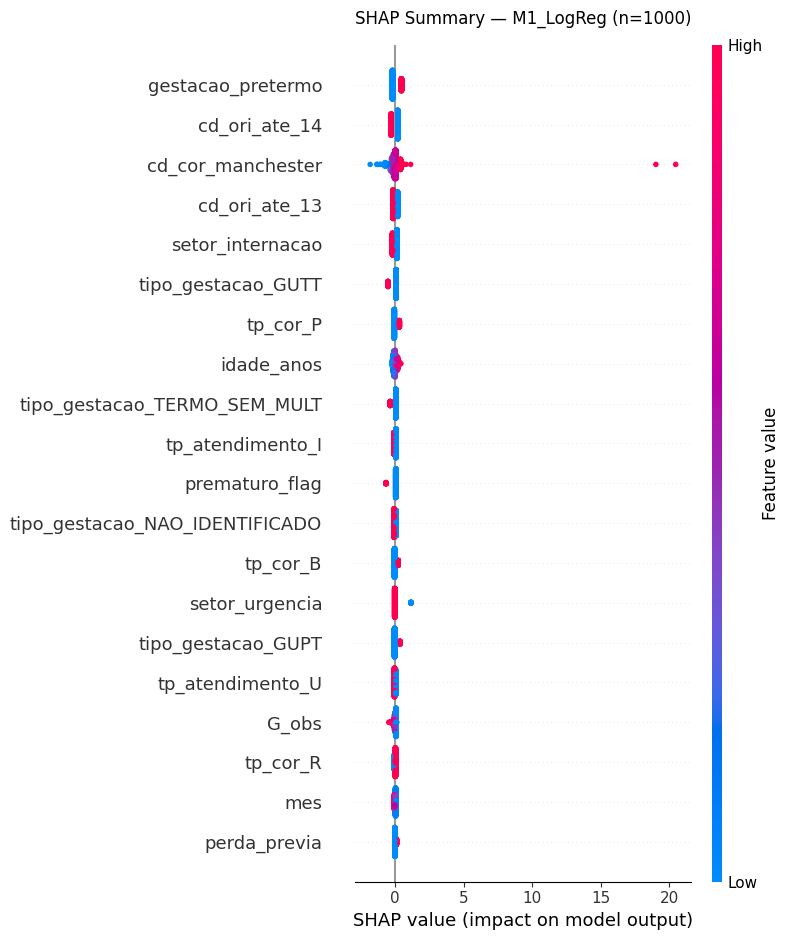

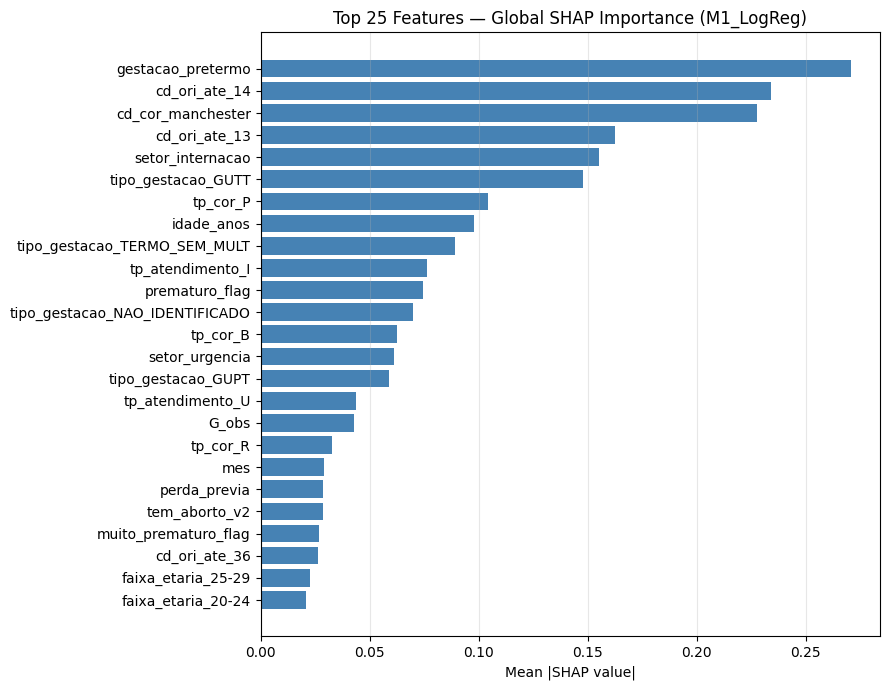

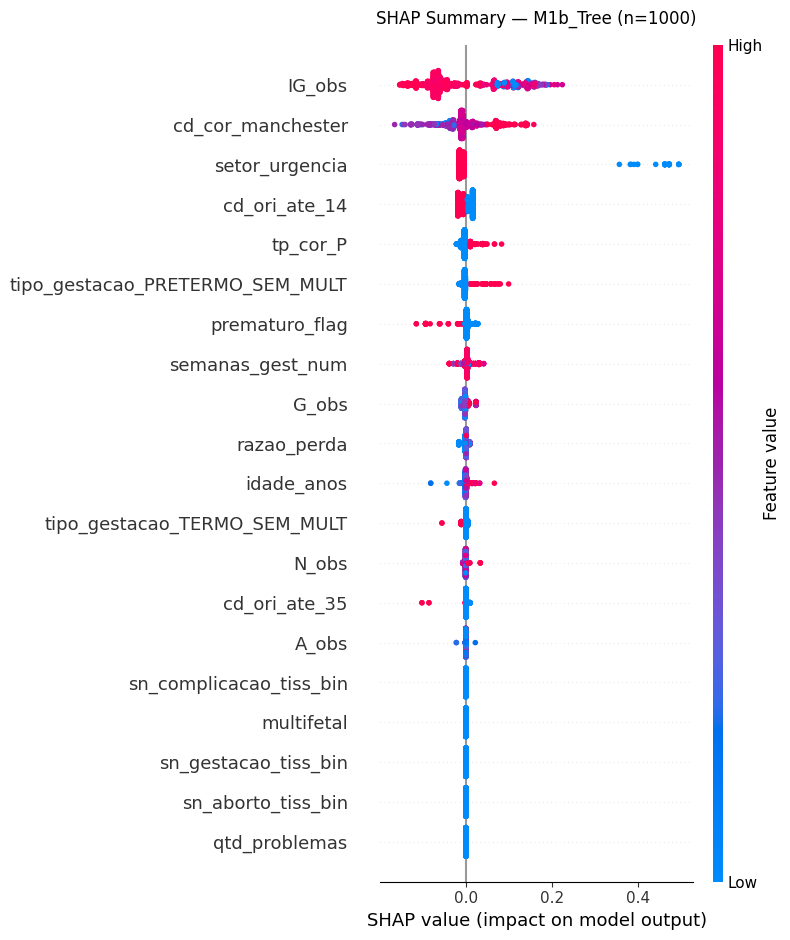

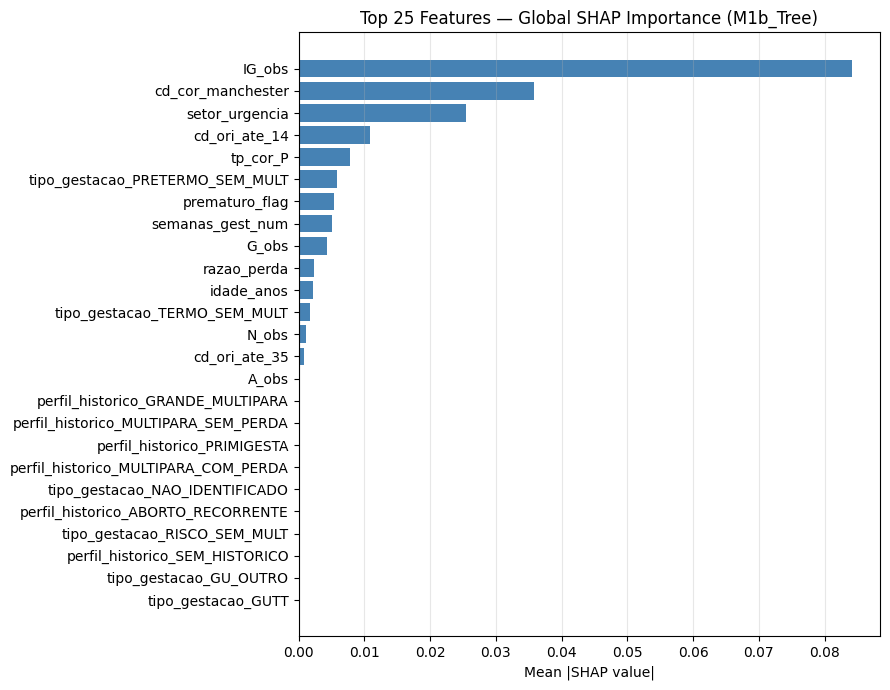

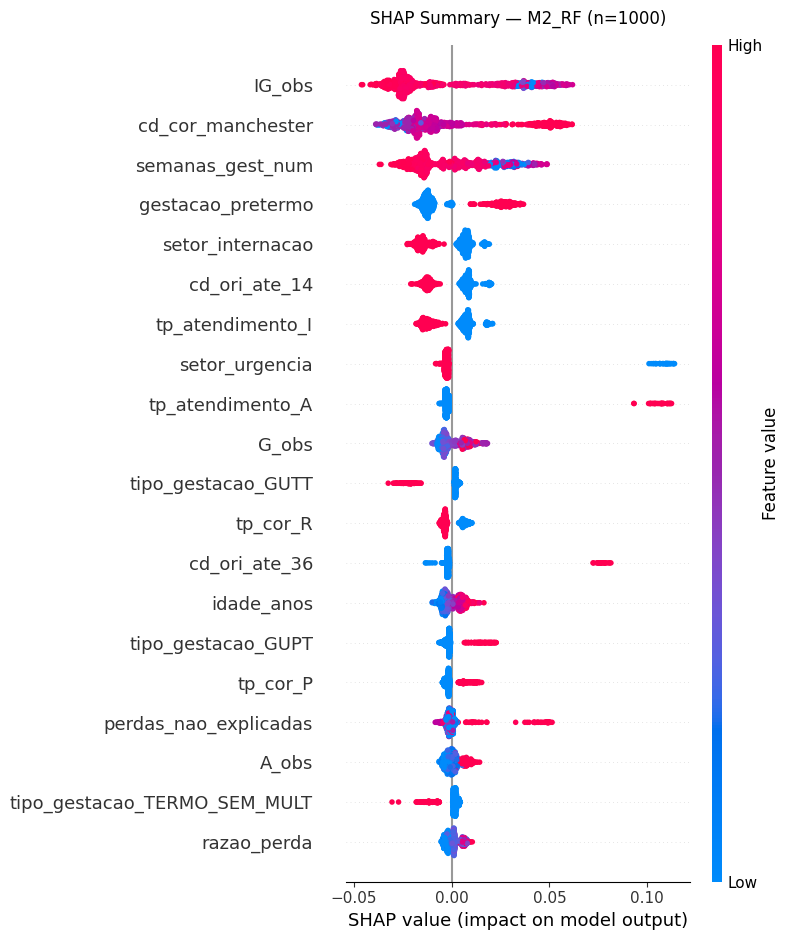

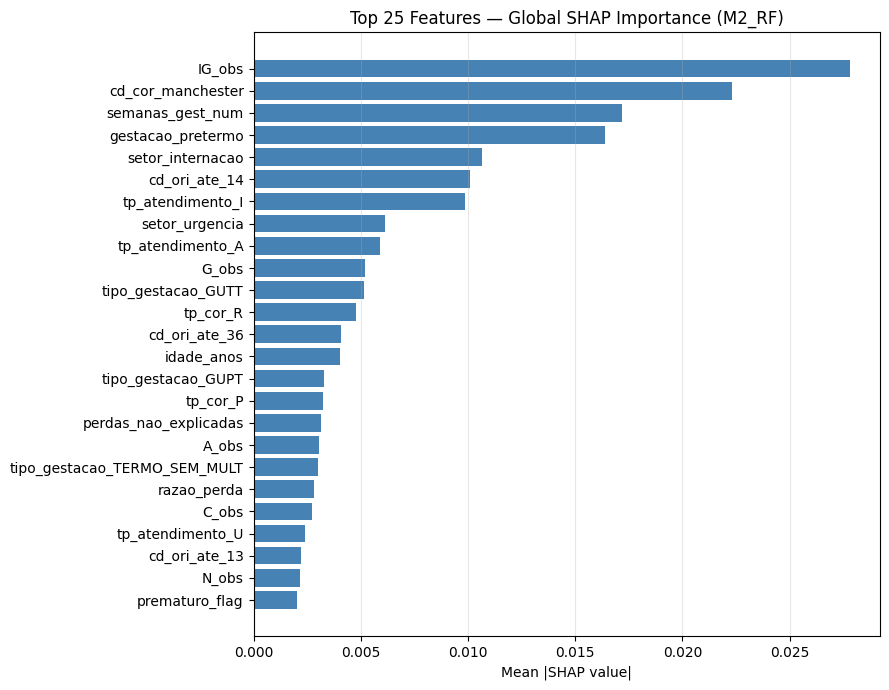

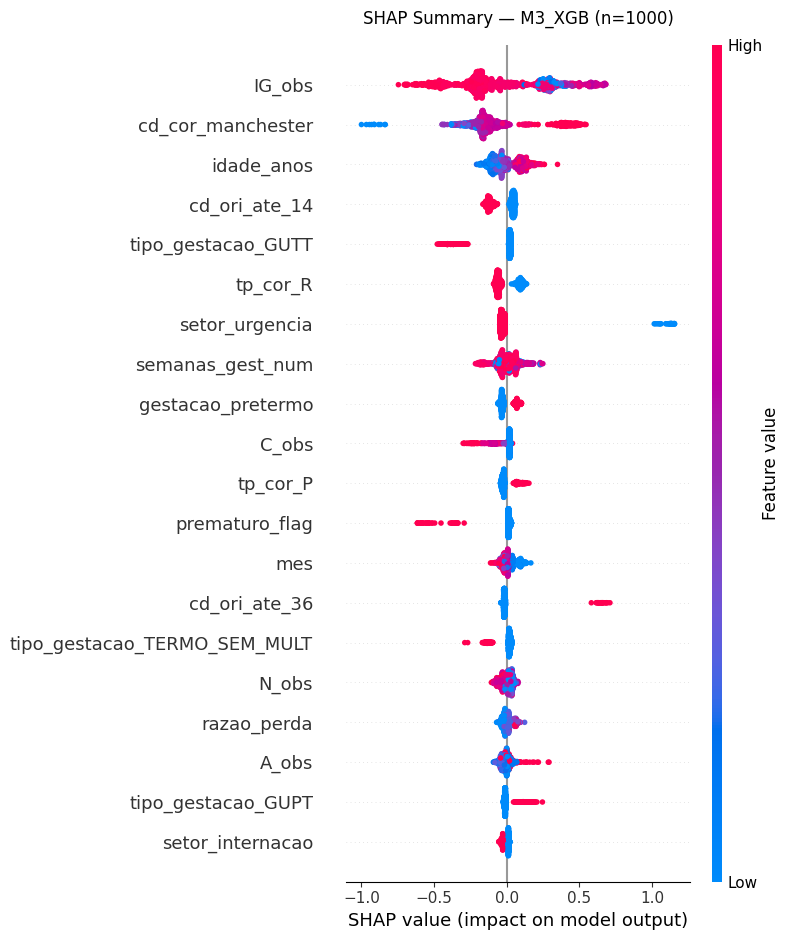

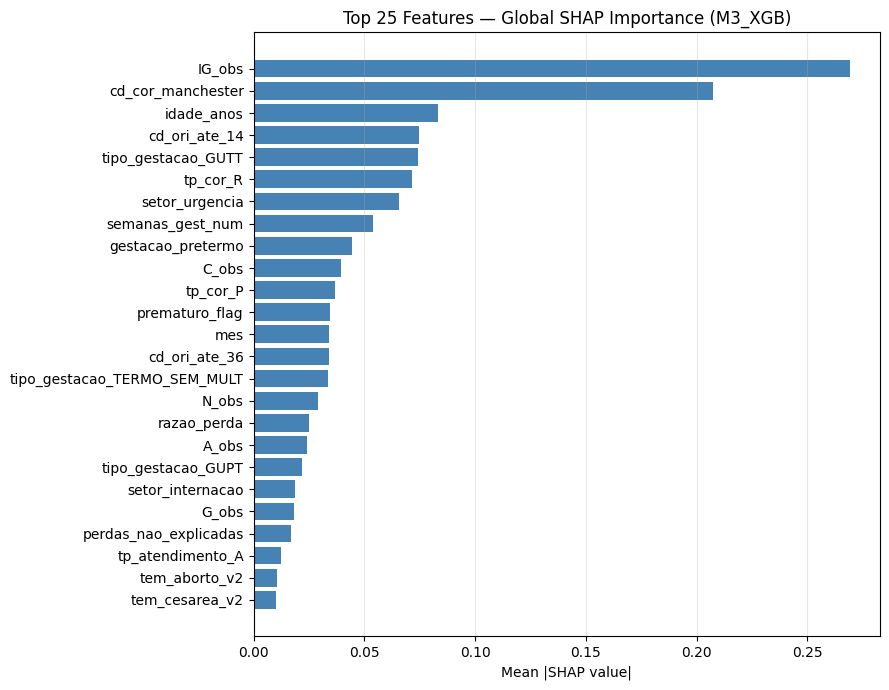

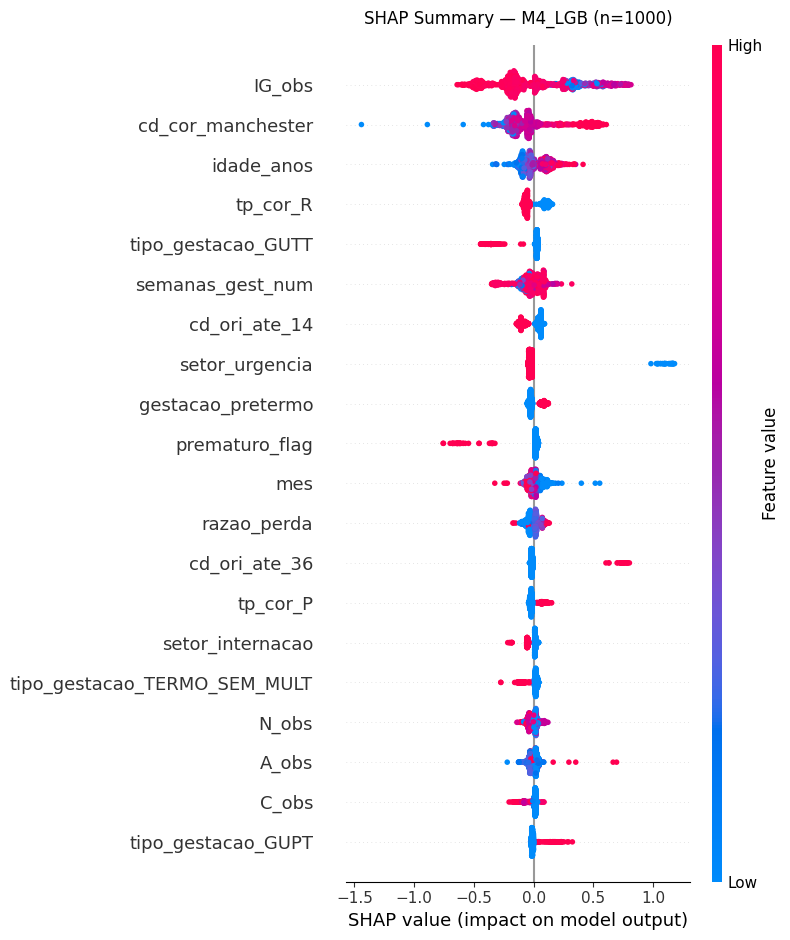

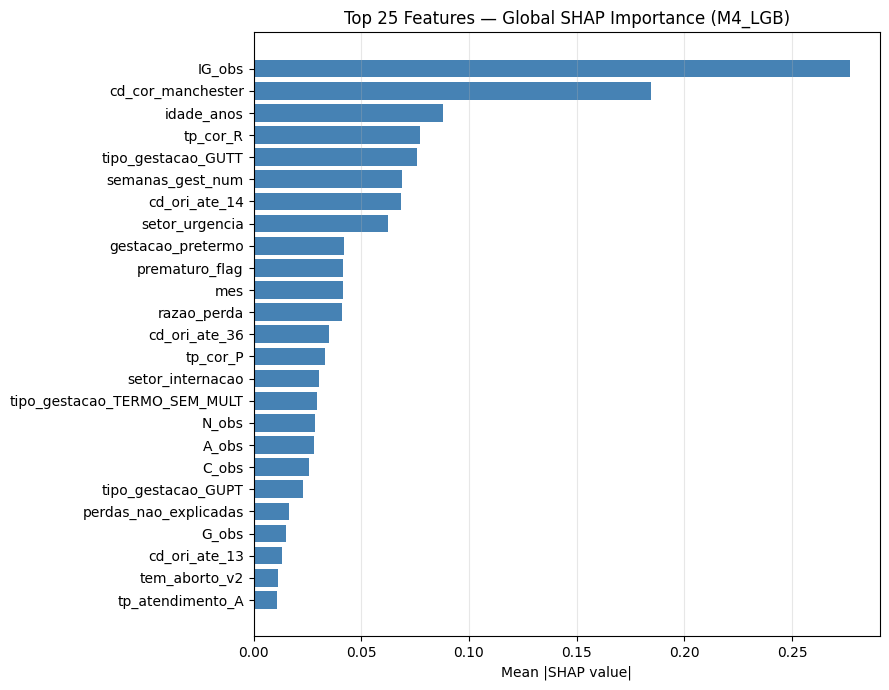

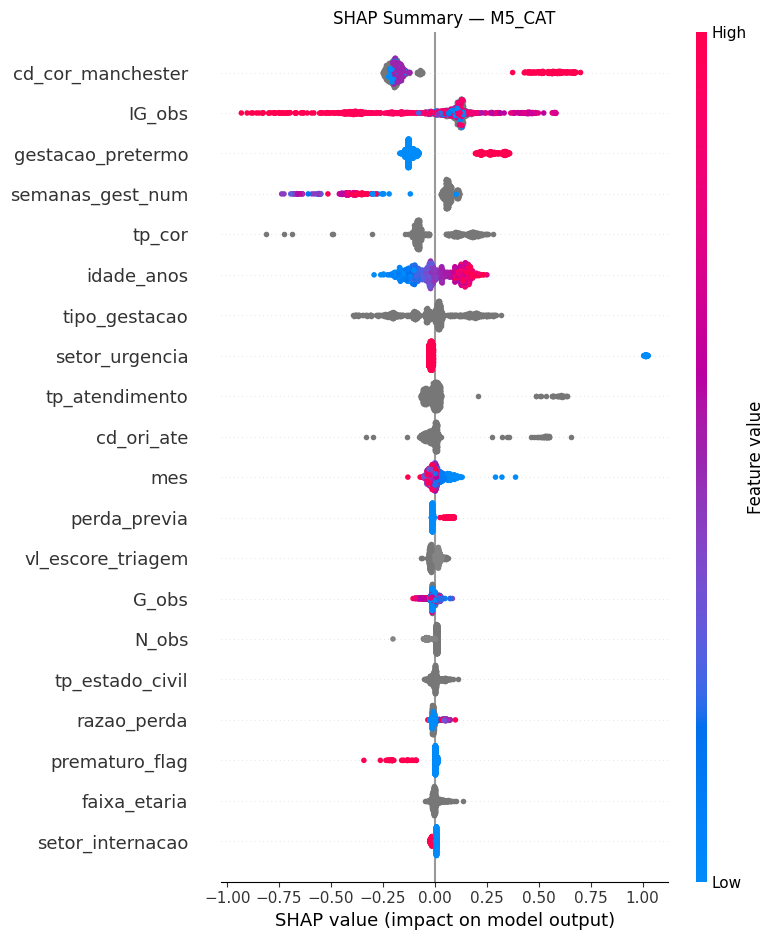

In [3]:
try:
    import shap
    from scipy import sparse

    try:
        feat_names_local = list(preproc.get_feature_names_out())
        feat_names_local = [n.split("__", 1)[-1] for n in feat_names_local]
    except AttributeError:
        feat_names_local = feat_names

    assert len(feat_names_local) == X_train_t.shape[1], (
        f"feat_names ({len(feat_names_local)}) != colunas transformadas ({X_train_t.shape[1]})"
    )

    rng = np.random.default_rng(42)
    idx_sample = rng.choice(len(X_test_t), size=min(1000, len(X_test_t)), replace=False)
    X_shap = X_test_t[idx_sample]
    X_shap_dense = X_shap.toarray() if sparse.issparse(X_shap) else np.asarray(X_shap)
    X_shap_plot = pd.DataFrame(X_shap_dense, columns=feat_names_local)

    modelos_shap = [n for n in modelos_fit if n != "M0_Dummy"]
    shap_rankings = []

    for modelo_shap_nome in modelos_shap:
        modelo_shap = modelos_fit[modelo_shap_nome]
        print(f"[SHAP] Usando modelo: {modelo_shap_nome}")

        if modelo_shap_nome == "M5_CAT" and HAS_CAT:
            # CatBoost SHAP com dados brutos
            explainer_cat = shap.TreeExplainer(modelo_shap)
            rng2 = np.random.default_rng(42)
            idx_s2 = rng2.choice(len(X_test), size=min(1000, len(X_test)), replace=False)
            X_cat_sample = X_test.iloc[idx_s2].reset_index(drop=True)
            shap_values_cat = explainer_cat.shap_values(X_cat_sample)
            if isinstance(shap_values_cat, list):
                shap_values_cat = shap_values_cat[1] if len(shap_values_cat) > 1 else shap_values_cat[0]
            if getattr(shap_values_cat, "ndim", 0) == 3:
                shap_values_cat = shap_values_cat[:, :, 1]
            shap_values_cat = np.asarray(shap_values_cat)
            # Plot com feature names do raw df
            cat_feat_names = list(X_test.columns)
            if shap_values_cat.shape[1] == len(cat_feat_names):
                plt.figure(figsize=(10, 8))
                shap.summary_plot(shap_values_cat, X_cat_sample,
                                   feature_names=cat_feat_names, max_display=20, show=False)
                plt.title(T["shap_summary_fmt"].format(nome=modelo_shap_nome))
                plt.tight_layout()
                plt.savefig(PLOT_DIR / f"03_shap_summary_{modelo_shap_nome}.png", dpi=150, bbox_inches="tight")
                plt.show(); plt.close()
                shap_mean_cat = np.abs(shap_values_cat).mean(axis=0)
                shap_df = (
                    pd.DataFrame({"modelo": modelo_shap_nome, "feature": cat_feat_names,
                                   "shap_mean": shap_mean_cat})
                    .sort_values("shap_mean", ascending=False).head(25)
                )
                shap_df.to_csv(OUT_DIR / f"shap_importancia_global_{modelo_shap_nome}.csv", index=False)
                shap_rankings.append(shap_df)
            continue

        if modelo_shap_nome in ["M1b_Tree", "M2_RF", "M3_XGB", "M4_LGB"]:
            explainer = shap.TreeExplainer(modelo_shap)
            shap_values = explainer.shap_values(X_shap_dense)
        else:
            explainer = shap.LinearExplainer(modelo_shap, X_shap_dense)
            shap_values = explainer.shap_values(X_shap_dense)

        if isinstance(shap_values, list):
            shap_values = shap_values[1] if len(shap_values) > 1 else shap_values[0]
        elif getattr(shap_values, "ndim", 0) == 3:
            shap_values = shap_values[:, :, 1]
        shap_values = np.asarray(shap_values)

        plt.figure(figsize=(10, 8))
        shap.summary_plot(shap_values, X_shap_plot, feature_names=feat_names_local,
                           max_display=20, show=False, plot_type="dot")
        plt.title(T["shap_summary_n_fmt"].format(nome=modelo_shap_nome, n=len(X_shap_plot)), pad=15)
        plt.tight_layout()
        plt.savefig(PLOT_DIR / f"03_shap_summary_{modelo_shap_nome}.png", dpi=150, bbox_inches="tight")
        plt.show(); plt.close()

        shap_mean = np.abs(shap_values).mean(axis=0)
        shap_df = (
            pd.DataFrame({"modelo": modelo_shap_nome, "feature": feat_names_local,
                           "shap_mean": shap_mean})
            .sort_values("shap_mean", ascending=False).head(25)
        )
        fig, ax = plt.subplots(figsize=(9, 7))
        ax.barh(shap_df["feature"][::-1], shap_df["shap_mean"][::-1], color="steelblue")
        ax.set_xlabel(T["shap_imp_xlabel"])
        ax.set_title(T["shap_imp_title_fmt"].format(nome=modelo_shap_nome))
        ax.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.savefig(PLOT_DIR / f"04_shap_importancia_{modelo_shap_nome}.png", dpi=150, bbox_inches="tight")
        plt.show(); plt.close()

        shap_df.to_csv(OUT_DIR / f"shap_importancia_global_{modelo_shap_nome}.csv", index=False)
        shap_rankings.append(shap_df)
        print("\nTop 10 features por SHAP:")
        print(shap_df.head(10).to_string(index=False))

    if shap_rankings:
        pd.concat(shap_rankings, ignore_index=True).to_csv(
            OUT_DIR / "shap_importancia_global_todos_modelos.csv", index=False
        )

except ImportError:
    print("SHAP não instalado: pip install shap")
except Exception as e:
    print(f"Erro ao calcular SHAP: {type(e).__name__}: {e}")
    raise

## 20. XAI Completo — SHAP Waterfall Individual + Dependence Plots + DCA

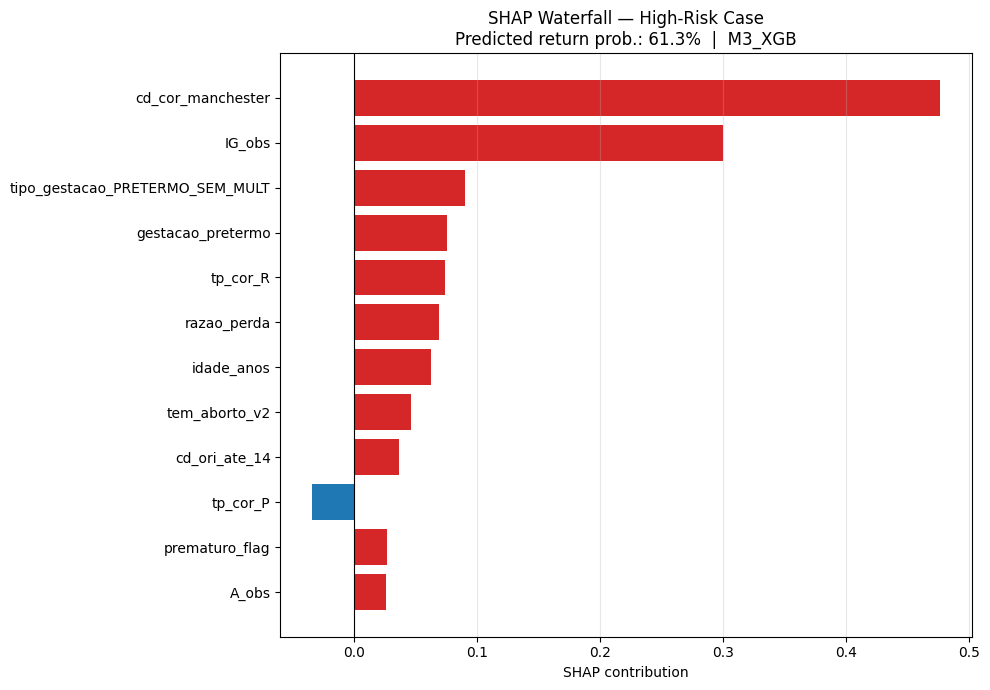

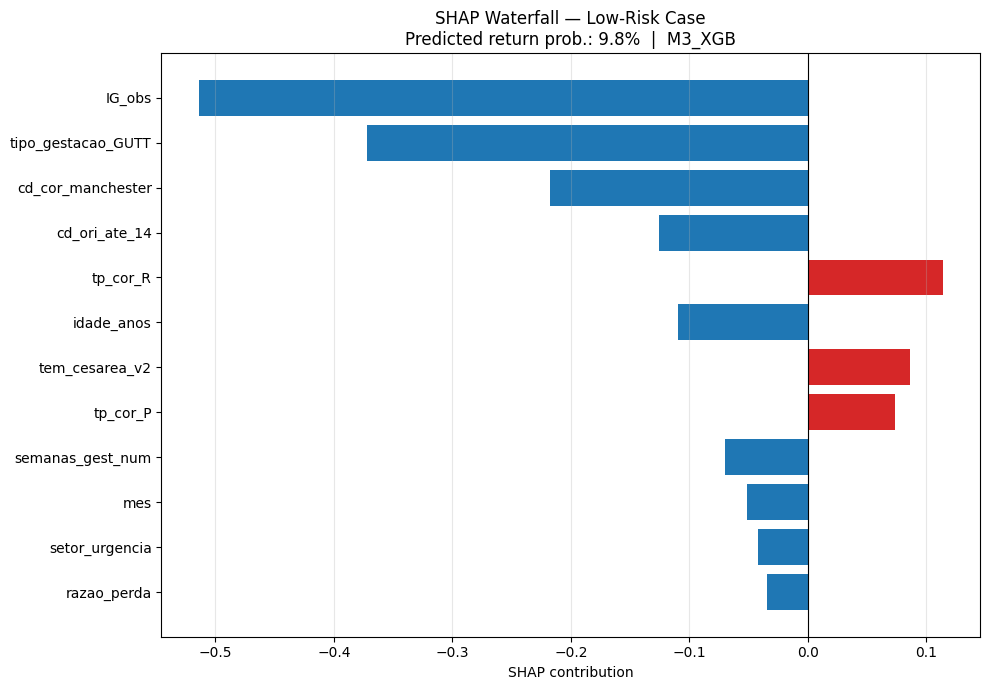

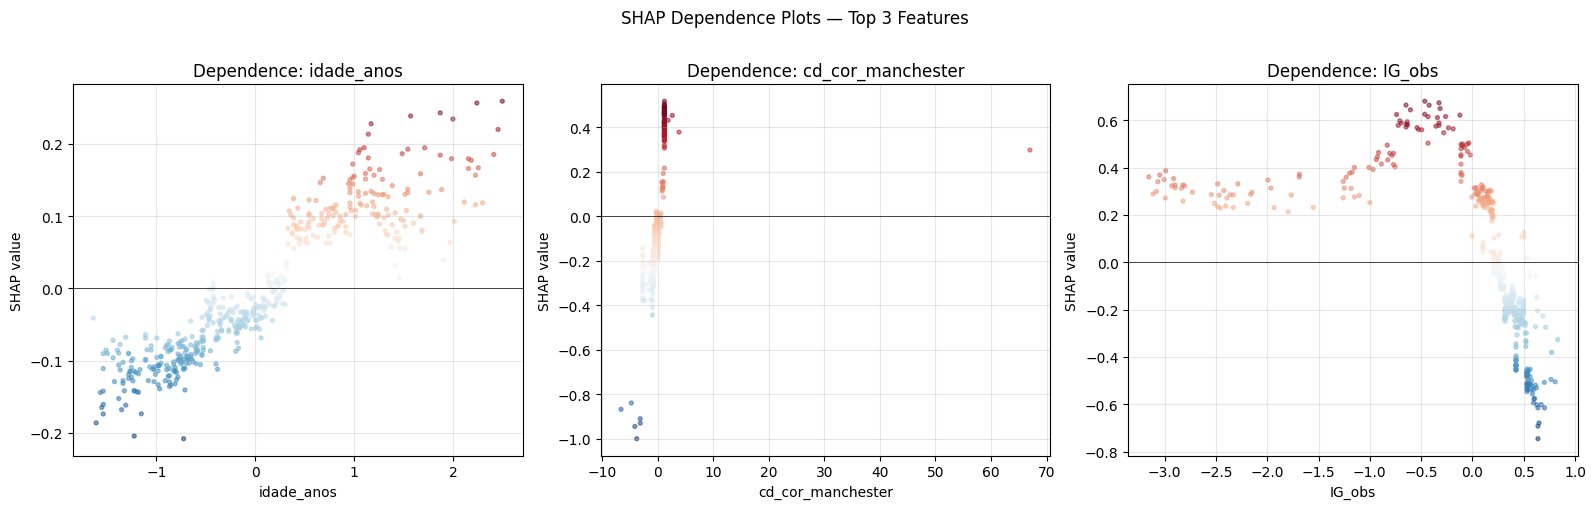

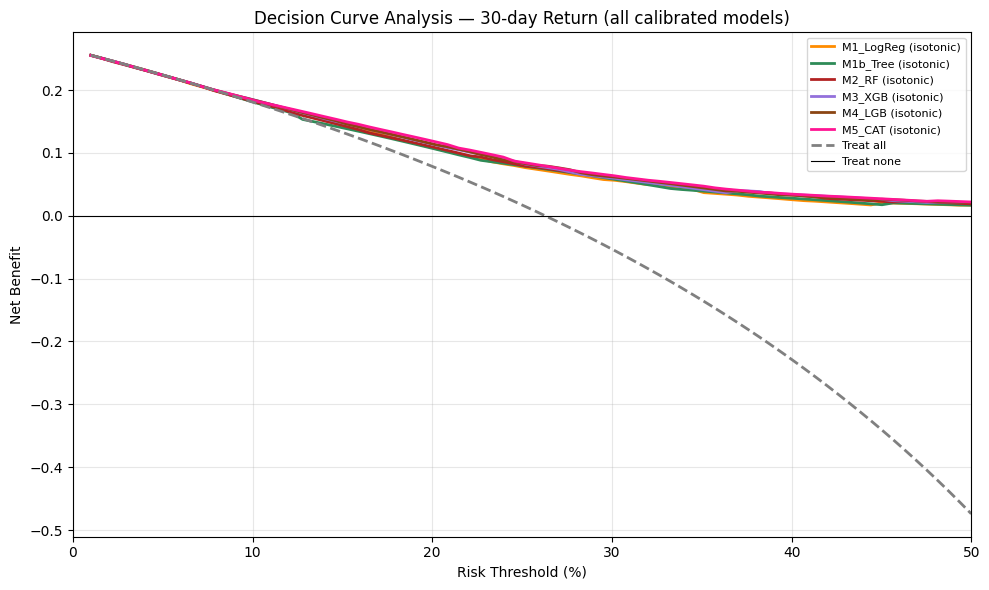

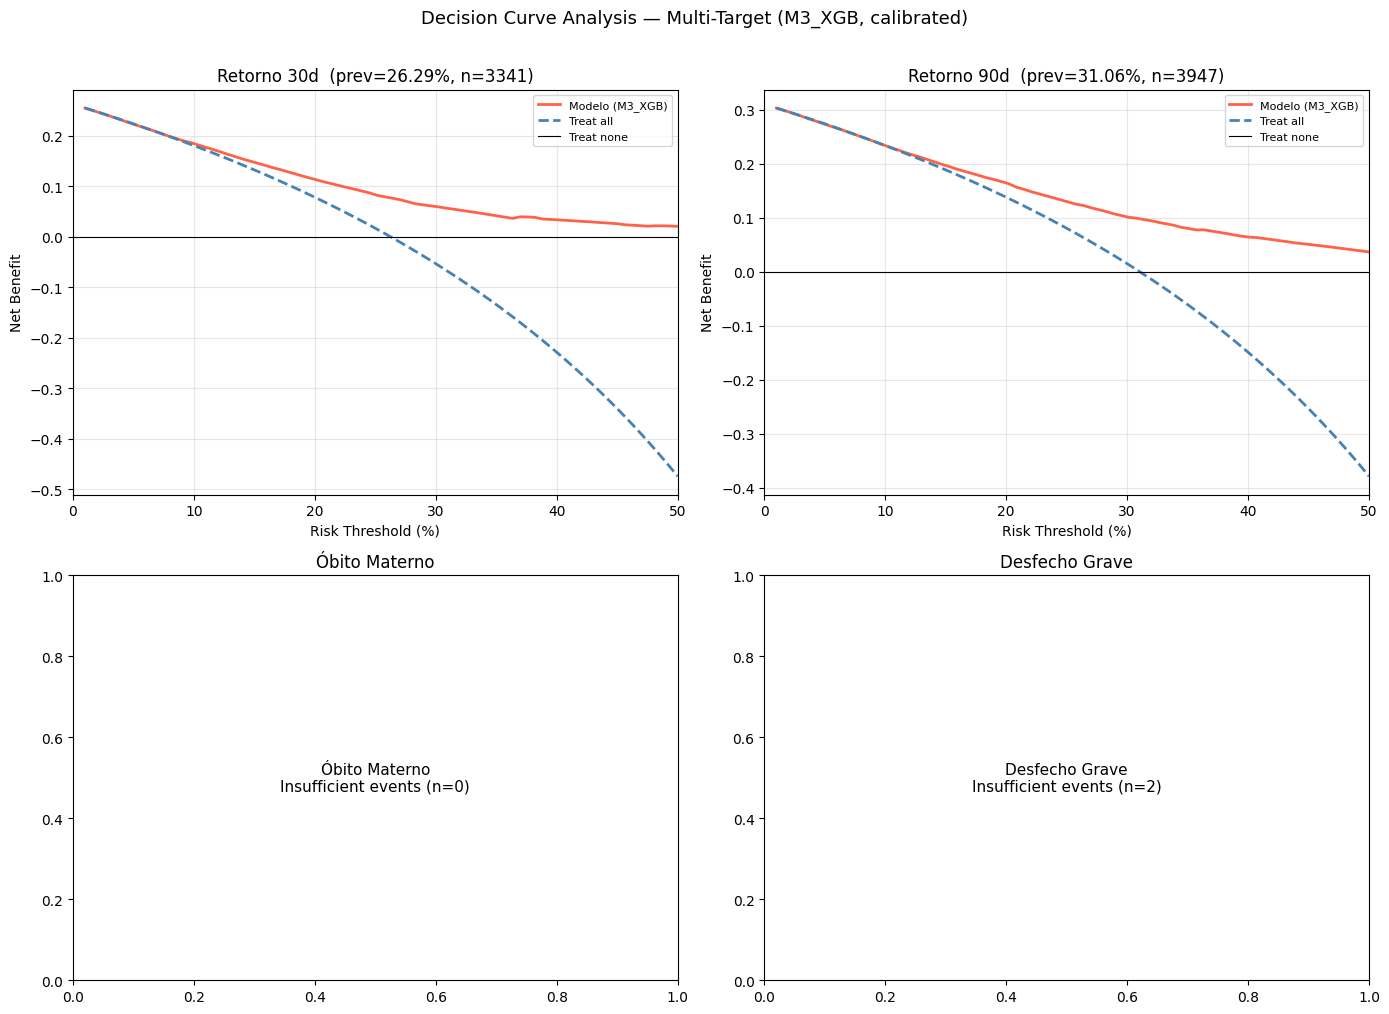

In [4]:
try:
    import shap as _shap
    from sklearn.isotonic import IsotonicRegression

    nome_xai = next(
        n for n in ["M3_XGB","M5_CAT","M4_LGB","M2_RF"] if n in modelos_fit
    )
    clf_xai = modelos_fit[nome_xai]
    print(f"[XAI] Modelo: {nome_xai}")

    feat_names_xai = [n.split("__",1)[-1] for n in preproc.get_feature_names_out()]
    rng = np.random.default_rng(42)
    idx_s = rng.choice(len(X_test_t), min(500, len(X_test_t)), replace=False)
    X_s = np.asarray(X_test_t[idx_s] if not hasattr(X_test_t[idx_s],"toarray")
                     else X_test_t[idx_s].toarray())

    if nome_xai == "M5_CAT" and HAS_CAT:
        explainer_xai = _shap.TreeExplainer(clf_xai)
        rng2 = np.random.default_rng(42)
        idx_s2 = rng2.choice(len(X_test), min(500, len(X_test)), replace=False)
        X_s_raw = X_test.iloc[idx_s2].reset_index(drop=True)
        sv = explainer_xai.shap_values(X_s_raw)
        if isinstance(sv, list): sv = sv[1]
        if getattr(sv, "ndim", 0) == 3: sv = sv[:, :, 1]
        sv = np.asarray(sv)
        feat_names_xai_actual = list(X_test.columns)
        X_s_df = X_s_raw
        probs_s = clf_xai.predict_proba(X_s_raw)[:, 1]
    else:
        explainer_xai = _shap.TreeExplainer(clf_xai)
        sv = explainer_xai.shap_values(X_s)
        if isinstance(sv, list): sv = sv[1]
        if getattr(sv,"ndim",0)==3: sv = sv[:,:,1]
        sv = np.asarray(sv)
        feat_names_xai_actual = feat_names_xai
        X_s_df = pd.DataFrame(X_s, columns=feat_names_xai)
        probs_s = probs_teste[nome_xai][idx_s]

    # SHAP Waterfall — alto risco
    alto_risco_idx = np.where(probs_s > 0.60)[0]
    if len(alto_risco_idx) > 0:
        caso_idx = alto_risco_idx[0]
        ev = explainer_xai.expected_value
        if isinstance(ev, (list, np.ndarray)): ev = ev[1]
        shap_caso = sv[caso_idx]
        top_n = 12
        sorted_idx = np.argsort(np.abs(shap_caso))[-top_n:]
        features_top = [feat_names_xai_actual[i] for i in sorted_idx]
        vals_top     = shap_caso[sorted_idx]
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.barh(features_top, vals_top,
                color=["#d62728" if v > 0 else "#1f77b4" for v in vals_top])
        ax.axvline(0, color="black", lw=0.8)
        ax.set_title(T["waterfall_hi_fmt"].format(prob=probs_s[caso_idx], nome=nome_xai))
        ax.set_xlabel(T["waterfall_xlabel"]); ax.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.savefig(PLOT_DIR/"08_shap_waterfall_alto_risco.png", dpi=150)
        plt.show(); plt.close()

    # SHAP Waterfall — baixo risco
    baixo_risco_idx = np.where(probs_s < 0.10)[0]
    if len(baixo_risco_idx) > 0:
        caso_idx = baixo_risco_idx[0]
        shap_caso = sv[caso_idx]
        sorted_idx = np.argsort(np.abs(shap_caso))[-top_n:]
        features_top = [feat_names_xai_actual[i] for i in sorted_idx]
        vals_top     = shap_caso[sorted_idx]
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.barh(features_top, vals_top,
                color=["#d62728" if v > 0 else "#1f77b4" for v in vals_top])
        ax.axvline(0, color="black", lw=0.8)
        ax.set_title(T["waterfall_lo_fmt"].format(prob=probs_s[caso_idx], nome=nome_xai))
        ax.set_xlabel(T["waterfall_xlabel"]); ax.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.savefig(PLOT_DIR/"09_shap_waterfall_baixo_risco.png", dpi=150)
        plt.show(); plt.close()

    # SHAP Dependence Plots — top 3 features
    shap_mean = np.abs(sv).mean(axis=0)
    top3_idx  = np.argsort(shap_mean)[-3:]
    fig, axes_dep = plt.subplots(1, 3, figsize=(16, 5))
    for ax_dep, feat_i in zip(axes_dep, top3_idx):
        feat_n = feat_names_xai_actual[feat_i]
        x_vals = X_s_df.iloc[:, feat_i] if hasattr(X_s_df, 'iloc') else X_s_df[:, feat_i]
        ax_dep.scatter(x_vals, sv[:, feat_i], c=sv[:, feat_i], cmap="RdBu_r", alpha=0.5, s=8)
        ax_dep.axhline(0, color="black", lw=0.5)
        ax_dep.set_xlabel(feat_n); ax_dep.set_ylabel(T["dep_ylabel"])
        ax_dep.set_title(f"Dependence: {feat_n}"); ax_dep.grid(alpha=0.3)
    plt.suptitle(T["dep_suptitle"], y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR/"10_shap_dependence.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()

    # ── Decision Curve Analysis ──────────────────────────────────────────────
    print("\n[XAI] Decision Curve Analysis — Todos os Modelos (calibrados):")

    DCA_CONFIG = {
        "y_retorno_30d":    {"range": (0.01, 0.50), "label": "Retorno 30d",    "xlim": (0, 50)},
        "y_retorno_90d":    {"range": (0.01, 0.50), "label": "Retorno 90d",    "xlim": (0, 50)},
        "y_obito_materno":  {"range": (0.001, 0.05),"label": "Óbito Materno",  "xlim": (0, 5)},
        "y_desfecho_grave": {"range": (0.001, 0.05),"label": "Desfecho Grave", "xlim": (0, 5)},
    }

    def _net_benefit(y_true, probs, thresholds):
        n = len(y_true)
        nb = []
        for pt in thresholds:
            yp = (probs >= pt).astype(int)
            tp = ((yp == 1) & (y_true == 1)).sum()
            fp = ((yp == 1) & (y_true == 0)).sum()
            nb.append(tp / n - fp / n * (pt / (1 - pt)))
        return np.array(nb)

    cfg_prim  = DCA_CONFIG["y_retorno_30d"]
    thr_prim  = np.linspace(cfg_prim["range"][0], cfg_prim["range"][1], 80)
    n_test_dca = len(y_test)

    fig_dca_all, ax_dca_all = plt.subplots(figsize=(10, 6))
    cores_dca = ["steelblue", "darkorange", "seagreen", "firebrick",
                 "mediumpurple", "saddlebrown", "deeppink", "teal"]
    rows_nne = []

    for idx_m, nome in enumerate(modelos_fit):
        if nome == "M0_Dummy":
            continue
        p_cal = probs_teste_cal.get(nome, probs_teste[nome])
        nb = _net_benefit(y_test, p_cal, thr_prim)
        cor = cores_dca[idx_m % len(cores_dca)]
        lbl_cal = f" ({metodo_escolhido.get(nome, 'raw')})" if nome in metodo_escolhido else ""
        ax_dca_all.plot(thr_prim * 100, nb, color=cor, lw=2, label=f"{nome}{lbl_cal}")
        mid = len(thr_prim) // 2
        nne_val = 1.0 / nb[mid] if nb[mid] > 1e-8 else float("inf")
        rows_nne.append({
            "target": "Retorno 30d", "modelo": nome, "calibrado": nome in probs_teste_cal,
            "threshold_ref_pct": round(thr_prim[mid] * 100, 2),
            "net_benefit": round(nb[mid], 6),
            "NNE": round(nne_val, 1) if nne_val < 1e6 else "Inf",
        })

    nb_all = _net_benefit(y_test, np.ones(n_test_dca), thr_prim)
    ax_dca_all.plot(thr_prim * 100, nb_all, color="gray", lw=2, ls="--", label=T["dca_treat_all"])
    ax_dca_all.axhline(0, color="black", lw=0.8, label=T["dca_treat_none"])
    ax_dca_all.set_xlabel(T["dca_xlabel"]); ax_dca_all.set_ylabel(T["dca_ylabel"])
    ax_dca_all.set_title(T["dca_title"])
    ax_dca_all.legend(fontsize=8, loc="upper right")
    ax_dca_all.grid(alpha=0.3); ax_dca_all.set_xlim(cfg_prim["xlim"])
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "11a_decision_curve_todos_modelos.png", dpi=150)
    plt.show(); plt.close()
    print("  Gerado: plots/11a_decision_curve_todos_modelos.png")

    # DCA Multi-Target 2×2
    clf_dca_nome = nome_xai
    clf_dca_base = modelos_fit[clf_dca_nome]
    fig_dca, axes_dca = plt.subplots(2, 2, figsize=(14, 10))
    axes_dca = axes_dca.ravel()

    for ax_i, (target_col, cfg) in enumerate(DCA_CONFIG.items()):
        y_te_dca = df_test[target_col].values
        prev_pct = y_te_dca.mean() * 100
        n_eventos = int(y_te_dca.sum())
        ax = axes_dca[ax_i]
        if n_eventos < 5:
            ax.text(0.5, 0.5, T["dca_insuf_fmt"].format(lbl=cfg['label'], n=n_eventos),
                    ha="center", va="center", fontsize=11, transform=ax.transAxes)
            ax.set_title(cfg["label"]); continue

        thresholds_dca = np.linspace(cfg["range"][0], cfg["range"][1], 80)
        if target_col == "y_retorno_30d":
            prob_dca = probs_teste_cal.get(clf_dca_nome, probs_teste[clf_dca_nome])
        else:
            try:
                if clf_dca_nome == "M5_CAT" and HAS_CAT:
                    try:
                        p_dca = clf_dca_base.get_params()
                    except Exception:
                        p_dca = {"iterations": 400, "depth": 5, "learning_rate": 0.05,
                                  "random_seed": 42, "verbose": 0, "nan_mode": "Min"}
                    clf_dca = CatBoostClassifier(**p_dca)
                    clf_dca.fit(X_train, df_train[target_col].values, verbose=0)
                    p_val_dca = clf_dca.predict_proba(X_valid)[:, 1]
                    p_tst_dca = clf_dca.predict_proba(X_test)[:, 1]
                else:
                    try:
                        clf_dca = clf_dca_base.__class__(**clf_dca_base.get_params())
                    except Exception:
                        clf_dca = clf_dca_base.__class__()
                    clf_dca.fit(X_train_t, df_train[target_col].values)
                    p_val_dca = clf_dca.predict_proba(X_valid_t)[:, 1]
                    p_tst_dca = clf_dca.predict_proba(X_test_t)[:, 1]
                iso_dca = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip")
                iso_dca.fit(p_val_dca, df_valid[target_col].values)
                prob_dca = iso_dca.predict(p_tst_dca)
            except Exception as e_dca:
                print(f"  {cfg['label']}: erro — {e_dca}"); continue

        nb_model = _net_benefit(y_te_dca, prob_dca, thresholds_dca)
        nb_all   = _net_benefit(y_te_dca, np.ones(len(y_te_dca)), thresholds_dca)
        ax.plot(thresholds_dca * 100, nb_model, color="tomato", lw=2, label=f"Modelo ({clf_dca_nome})")
        ax.plot(thresholds_dca * 100, nb_all, color="steelblue", lw=2, ls="--", label=T["dca_treat_all"])
        ax.axhline(0, color="black", lw=0.8, label=T["dca_treat_none"])
        ax.set_xlabel(T["dca_xlabel"]); ax.set_ylabel(T["dca_ylabel"])
        ax.set_title(f"{cfg['label']}  (prev={prev_pct:.2f}%, n={n_eventos})")
        ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3); ax.set_xlim(cfg["xlim"])
        mid_idx = len(thresholds_dca) // 2
        nb_mid  = nb_model[mid_idx]
        nne_val = 1.0 / nb_mid if nb_mid > 1e-8 else float("inf")
        rows_nne.append({
            "target": cfg["label"], "modelo": clf_dca_nome, "calibrado": True,
            "threshold_ref_pct": round(thresholds_dca[mid_idx] * 100, 2),
            "net_benefit": round(nb_mid, 6),
            "NNE": round(nne_val, 1) if nne_val < 1e6 else "Inf",
        })

    plt.suptitle(T["dca_mt_title_fmt"].format(nome=clf_dca_nome),
                 fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "11b_decision_curve_multi_target.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()

    df_nne = pd.DataFrame(rows_nne)
    df_nne.to_csv(OUT_DIR / "nne_por_target.csv", index=False)
    print("\n  NNE (Number Needed to Examine):"); print(df_nne.to_string(index=False))
    print("  Gerado: plots/11b_decision_curve_multi_target.png")

except ImportError:
    print("SHAP não instalado: pip install shap")
except Exception as e:
    print(f"Erro XAI: {type(e).__name__}: {e}")

## 12. LIME — Local Interpretable Model-Agnostic Explanations

In [5]:
try:
    from lime import lime_tabular

    print("\n" + "="*60)
    print("[LIME] Calculando explicações locais...")
    print("="*60)

    # ── Variáveis auxiliares (recomputadas caso SHAP tenha falhado) ───
    try:
        _fn_out = list(preproc.get_feature_names_out())
        _feat_names_dense = [n.split("__", 1)[-1] for n in _fn_out]
    except Exception:
        _feat_names_dense = feat_names

    # LIME requer array denso; preferir modelo não-CatBoost
    _nome_lime = next(
        (n for n in ["M3_XGB", "M4_LGB", "M2_RF", "M1b_Tree", "M1_LogReg"]
         if n in modelos_fit),
        None,
    )
    if _nome_lime is None:
        raise RuntimeError("Nenhum modelo adequado para LIME encontrado.")

    _clf_lime = modelos_fit[_nome_lime]

    # Dados de treino (background) — densos
    X_bg_lime = (X_train_t.toarray() if _sp.issparse(X_train_t)
                 else np.asarray(X_train_t))
    X_tst_lime = (X_test_t.toarray() if _sp.issparse(X_test_t)
                  else np.asarray(X_test_t))

    _lime_exp = lime_tabular.LimeTabularExplainer(
        training_data=X_bg_lime,
        feature_names=_feat_names_dense,
        class_names=["sem_retorno", "retorno_30d"],
        mode="classification",
        random_state=42,
        discretize_continuous=False,
    )

    def _lime_predict_fn(X_arr):
        return _clf_lime.predict_proba(X_arr)

    # ── Amostra balanceada: metade alto risco, metade baixo ───────────
    _probs_lime = (probs_teste_cal.get(_nome_lime)
                   or probs_teste.get(_nome_lime, np.full(len(y_test), 0.5)))
    _rng_lime = np.random.default_rng(42)

    _hi_idx = np.where(_probs_lime >= np.percentile(_probs_lime, 80))[0]
    _lo_idx = np.where(_probs_lime <= np.percentile(_probs_lime, 20))[0]
    _n_each = 15
    _hi_sel = _rng_lime.choice(_hi_idx, min(_n_each, len(_hi_idx)), replace=False)
    _lo_sel = _rng_lime.choice(_lo_idx, min(_n_each, len(_lo_idx)), replace=False)
    _lime_idx = np.concatenate([_hi_sel, _lo_sel])
    N_LIME = len(_lime_idx)

    # ── Compute LIME para cada instância ─────────────────────────────
    _lime_weights: dict[str, list[float]] = {}
    _lime_rows = []

    for _inst_i in _lime_idx:
        _exp = _lime_exp.explain_instance(
            X_tst_lime[_inst_i],
            _lime_predict_fn,
            num_features=15,
            labels=(1,),           # sempre explica a classe positiva (retorno)
        )
        for _feat_str, _w in _exp.as_list(label=1):
            # LIME inclui condição no nome (ex: "G_obs <= 3.00") — pegar só a feature
            _fname = _feat_str.split(" ")[0]
            _lime_weights.setdefault(_fname, []).append(_w)
            _lime_rows.append({
                "instancia_idx": int(_inst_i),
                "grupo": "alto_risco" if _inst_i in _hi_sel else "baixo_risco",
                "prob_pred": round(float(_probs_lime[_inst_i]), 4),
                "feature_lime": _feat_str,
                "feature_nome": _fname,
                "peso": round(_w, 6),
            })

    # ── Importância LIME global (média |peso| sobre instâncias) ──────
    _lime_global = {f: np.mean(np.abs(ws)) for f, ws in _lime_weights.items()}
    _lime_global_df = (
        pd.DataFrame({"feature": list(_lime_global.keys()),
                      "lime_mean_abs_weight": list(_lime_global.values())})
        .sort_values("lime_mean_abs_weight", ascending=False)
        .head(25)
        .reset_index(drop=True)
    )

    fig_lime, ax_lime = plt.subplots(figsize=(9, 7))
    ax_lime.barh(_lime_global_df["feature"][::-1],
                 _lime_global_df["lime_mean_abs_weight"][::-1],
                 color="darkorange")
    ax_lime.set_xlabel(T["lime_imp_xlabel"])
    ax_lime.set_title(T["lime_imp_title"].format(n=N_LIME, nome=_nome_lime))
    ax_lime.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "12a_lime_importancia_global.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: 12a_lime_importancia_global.png")

    # ── Waterfall LIME — caso alto risco ─────────────────────────────
    for _wf_tag, _wf_idx_pool, _wf_key in [
        ("alto", _hi_sel, "lime_wf_hi_fmt"),
        ("baixo", _lo_sel, "lime_wf_lo_fmt"),
    ]:
        if len(_wf_idx_pool) == 0:
            continue
        _ci = _wf_idx_pool[0]
        _exp_wf = _lime_exp.explain_instance(
            X_tst_lime[_ci], _lime_predict_fn, num_features=12, labels=(1,)
        )
        _feats_wf = _exp_wf.as_list(label=1)
        _names_wf = [f[0] for f in _feats_wf]
        _vals_wf  = [f[1] for f in _feats_wf]
        fig_lw, ax_lw = plt.subplots(figsize=(10, 7))
        ax_lw.barh(_names_wf, _vals_wf,
                   color=["#d62728" if v > 0 else "#1f77b4" for v in _vals_wf])
        ax_lw.axvline(0, color="black", lw=0.8)
        ax_lw.set_title(T[_wf_key].format(prob=float(_probs_lime[_ci]), nome=_nome_lime))
        ax_lw.set_xlabel(T["lime_weight_xlabel"]); ax_lw.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        _wf_fname = f"12b_lime_waterfall_{_wf_tag}_risco.png"
        plt.savefig(PLOT_DIR / _wf_fname, dpi=150, bbox_inches="tight")
        plt.show(); plt.close()
        print(f"  Gerado: {_wf_fname}")

    # ── Salva CSVs ────────────────────────────────────────────────────
    _lime_global_df.to_csv(OUT_DIR / "lime_importancia_global.csv", index=False)
    pd.DataFrame(_lime_rows).to_csv(OUT_DIR / "lime_instancias.csv", index=False)
    print(f"\n  Top 10 features (LIME global):")
    print(_lime_global_df.head(10).to_string(index=False))

except ImportError:
    print("[LIME] lime não instalado: pip install lime")
except Exception as _e_lime:
    print(f"[LIME] Erro: {type(_e_lime).__name__}: {_e_lime}")
    import traceback; traceback.print_exc()

## 13. Permutation Feature Importance (XAI — agnóstico de modelo)

Mede o quanto o AUC-ROC cai quando cada feature é embaralhada.
Vantagem: não depende de gradientes nem SHAP values — funciona com qualquer estimador.
Referência: Breiman (2001), Fisher et al. (2019)

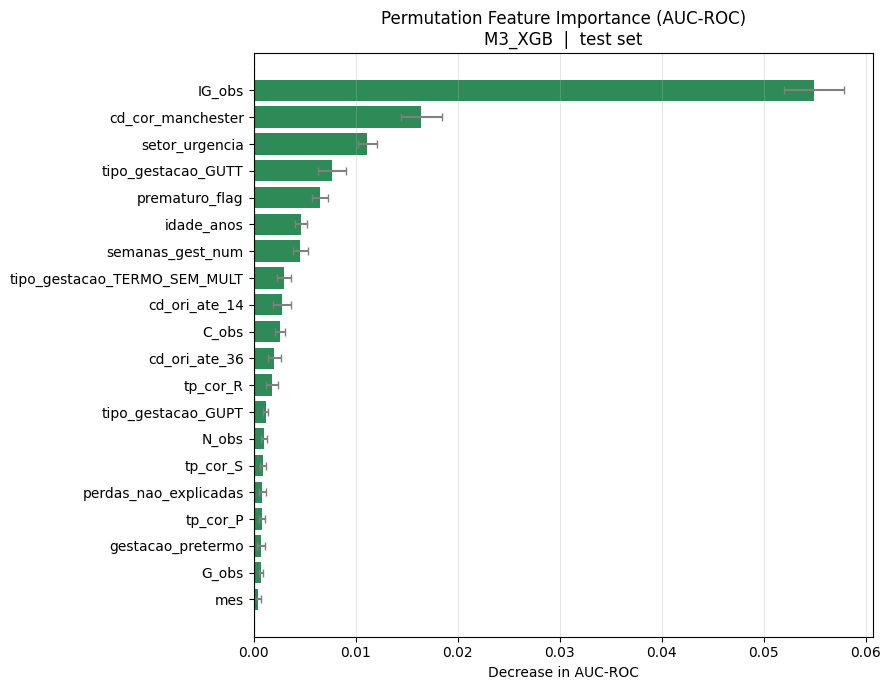

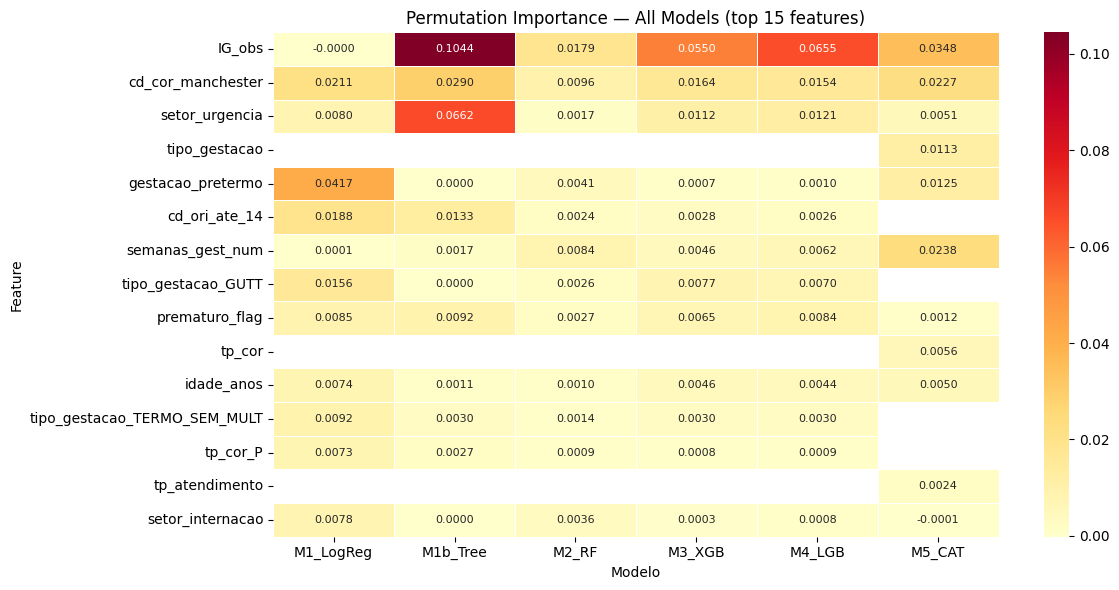

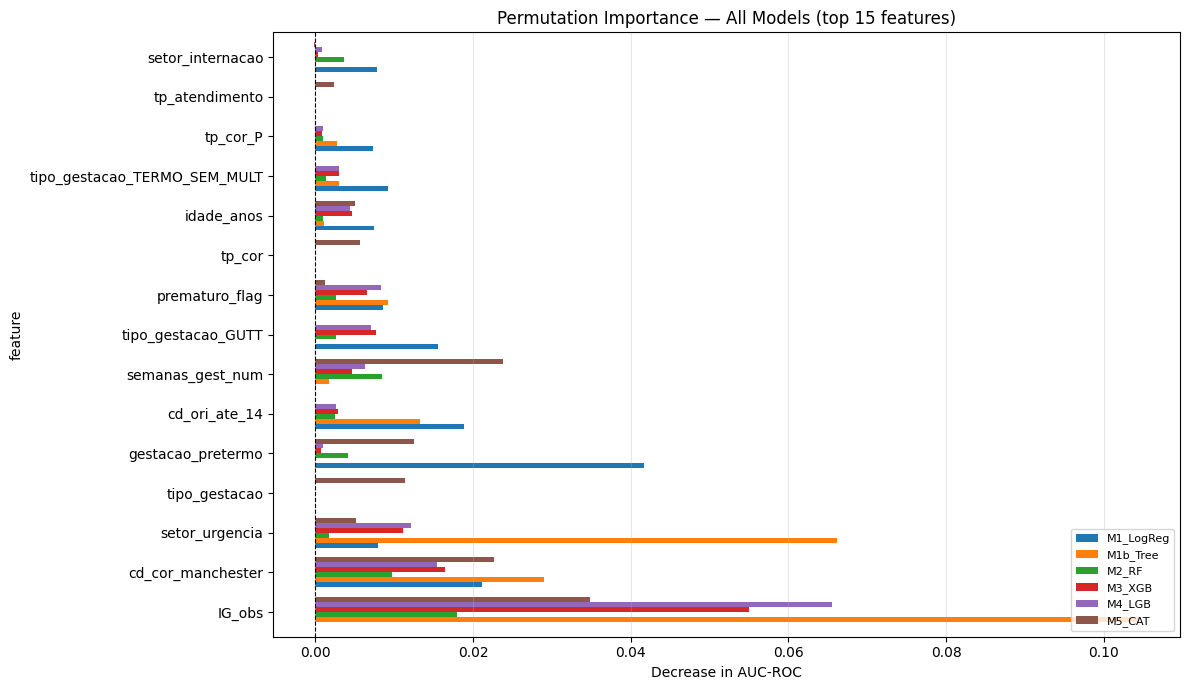

In [6]:
try:
    from sklearn.inspection import permutation_importance as _perm_imp

    print("\n" + "="*60)
    print("[Permutation] Calculando importância por permutação...")
    print("="*60)

    try:
        _fn_out2 = list(preproc.get_feature_names_out())
        _feat_names_perm = [n.split("__", 1)[-1] for n in _fn_out2]
    except Exception:
        _feat_names_perm = feat_names

    _perm_all = []
    N_REPEATS_PERM = 15

    for _nome_p, _clf_p in modelos_fit.items():
        if _nome_p == "M0_Dummy":
            continue

        if _nome_p == "M5_CAT" and HAS_CAT:
            _X_perm, _fnames_p = X_test, list(X_test.columns)
        else:
            _X_perm, _fnames_p = X_test_t, _feat_names_perm

        print(f"  [{_nome_p}] n_repeats={N_REPEATS_PERM}...", end=" ", flush=True)
        try:
            _res_perm = _perm_imp(
                _clf_p, _X_perm, y_test,
                n_repeats=N_REPEATS_PERM, random_state=42,
                scoring="roc_auc", n_jobs=-1,
            )
        except Exception:
            _res_perm = _perm_imp(
                _clf_p, _X_perm, y_test,
                n_repeats=N_REPEATS_PERM, random_state=42,
                scoring="roc_auc",
            )
        print("OK")

        _perm_df = (
            pd.DataFrame({
                "modelo":     _nome_p,
                "feature":    _fnames_p,
                "perm_mean":  _res_perm.importances_mean,
                "perm_std":   _res_perm.importances_std,
            })
            .sort_values("perm_mean", ascending=False)
            .reset_index(drop=True)
        )
        _perm_all.append(_perm_df)

    _all_perm_df = pd.concat(_perm_all, ignore_index=True)

    # ── Gráfico: melhor modelo (mesmo que SHAP) ──────────────────────
    _nome_perm_best = next(
        (n for n in ["M3_XGB", "M4_LGB", "M2_RF", "M1b_Tree", "M1_LogReg"]
         if n in modelos_fit), list(modelos_fit.keys())[1]
    )
    _best_perm = _all_perm_df[_all_perm_df["modelo"] == _nome_perm_best].head(20)

    fig_perm, ax_perm = plt.subplots(figsize=(9, 7))
    ax_perm.barh(
        _best_perm["feature"][::-1],
        _best_perm["perm_mean"][::-1],
        xerr=_best_perm["perm_std"][::-1],
        capsize=3, color="seagreen", ecolor="gray",
    )
    ax_perm.axvline(0, color="black", lw=0.8, ls="--")
    ax_perm.set_xlabel(T["perm_imp_xlabel"])
    ax_perm.set_title(T["perm_imp_title"].format(nome=_nome_perm_best))
    ax_perm.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "13a_perm_importance.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: 13a_perm_importance.png")

    # ── Heatmap comparativo: top 15 features × todos os modelos ──────
    _feat_rank_perm = (
        _all_perm_df.groupby("feature")["perm_mean"]
        .mean().sort_values(ascending=False).head(15).index.tolist()
    )
    _pivot_perm = (
        _all_perm_df[_all_perm_df["feature"].isin(_feat_rank_perm)]
        .pivot_table(index="feature", columns="modelo", values="perm_mean")
        .reindex(_feat_rank_perm)
    )
    fig_ph, ax_ph = plt.subplots(figsize=(12, 6))
    sns.heatmap(
        _pivot_perm, ax=ax_ph, annot=True, fmt=".4f",
        cmap="YlOrRd", linewidths=0.4,
        annot_kws={"size": 8},
    )
    ax_ph.set_title(T["perm_multi_title"])
    ax_ph.set_ylabel("Feature"); ax_ph.set_xlabel("Modelo")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "13b_perm_importance_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: 13b_perm_importance_heatmap.png")

    # ── Multi-bar comparativo ─────────────────────────────────────────
    _pivot_bar = _pivot_perm.fillna(0)
    fig_pb, ax_pb = plt.subplots(figsize=(12, 7))
    _pivot_bar.plot(kind="barh", ax=ax_pb, width=0.75)
    ax_pb.axvline(0, color="black", lw=0.8, ls="--")
    ax_pb.set_title(T["perm_multi_title"])
    ax_pb.set_xlabel(T["perm_imp_xlabel"])
    ax_pb.legend(fontsize=8, loc="lower right")
    ax_pb.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "13c_perm_importance_bar_modelos.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: 13c_perm_importance_bar_modelos.png")

    _all_perm_df.to_csv(OUT_DIR / "perm_importance_todos_modelos.csv", index=False)
    print(f"\n  Top 10 features ({_nome_perm_best}):")
    print(_best_perm.head(10)[["feature","perm_mean","perm_std"]].to_string(index=False))

except Exception as _e_perm:
    print(f"[Permutation] Erro: {type(_e_perm).__name__}: {_e_perm}")
    import traceback; traceback.print_exc()

## 14. ALE — Accumulated Local Effects (IAI — efeito marginal acumulado)

ALE corrige o viés do PDP em features correlacionadas: em vez de marginalizar
sobre a distribuição conjunta (PDP), acumula diferenças locais condicionais.
Referência: Apley & Zhu (2020) — "Visualizing the effects of predictor variables
in black box supervised learning models", JRSS-B.

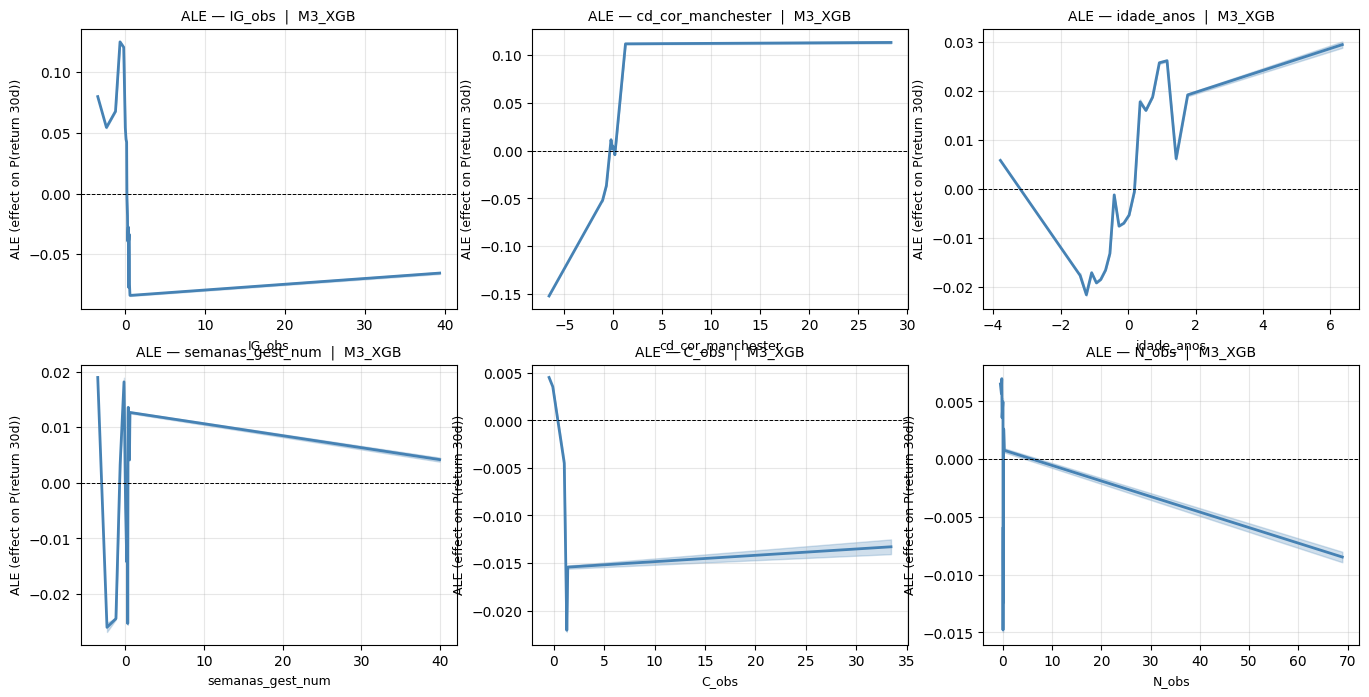

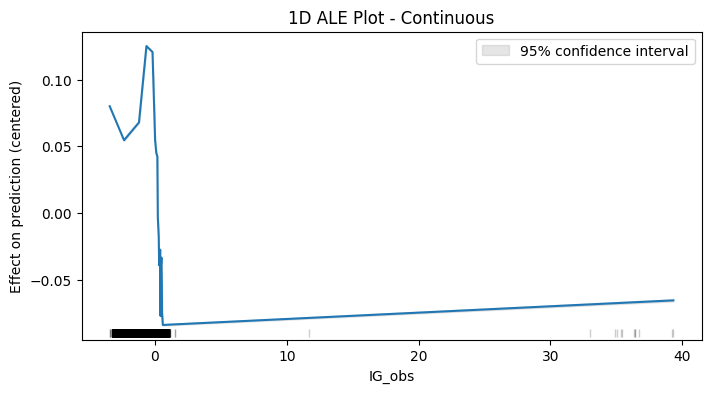

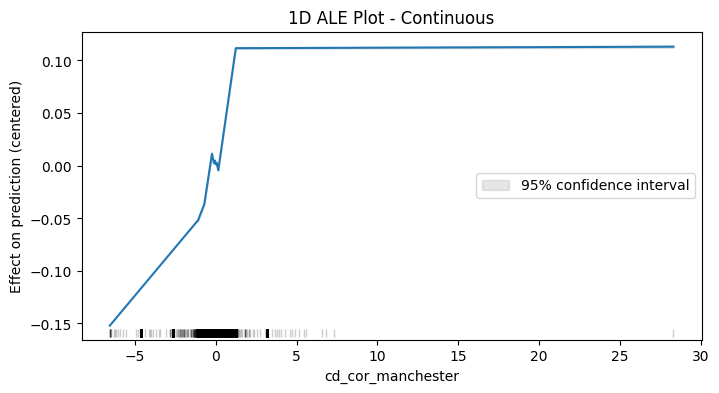

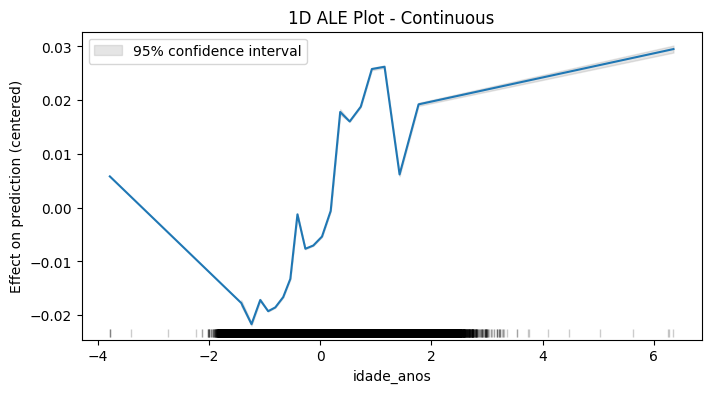

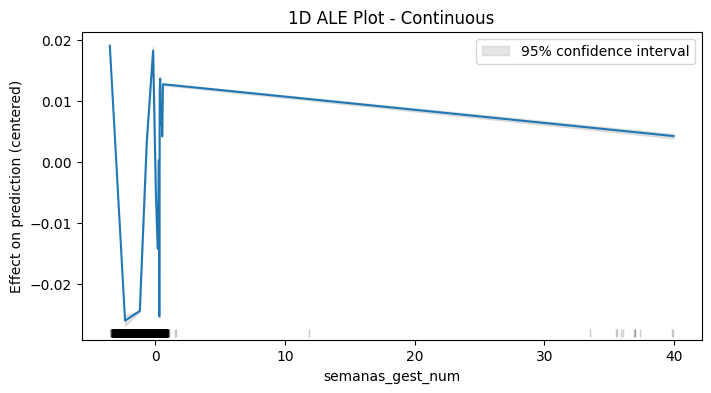

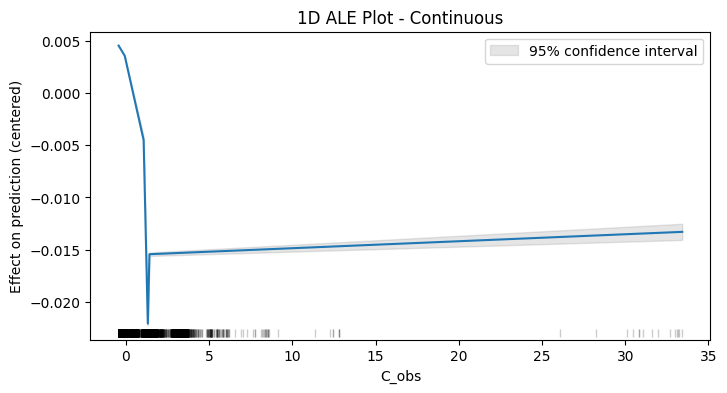

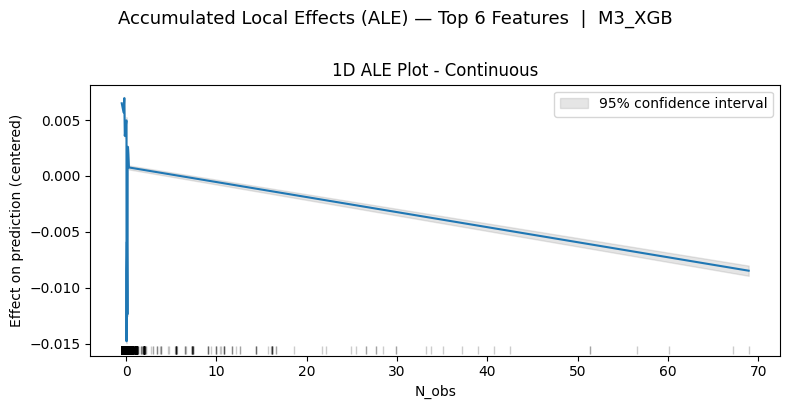

In [7]:
try:
    from PyALE import ale as _ale_fn

    print("\n" + "="*60)
    print("[ALE] Calculando Accumulated Local Effects...")
    print("="*60)

    try:
        _fn_out3 = list(preproc.get_feature_names_out())
        _feat_names_ale = [n.split("__", 1)[-1] for n in _fn_out3]
    except Exception:
        _feat_names_ale = feat_names

    # Modelo preferencial (não-CAT para dados transformados)
    _nome_ale = next(
        (n for n in ["M3_XGB", "M4_LGB", "M2_RF", "M1b_Tree"]
         if n in modelos_fit), None
    )
    if _nome_ale is None:
        raise RuntimeError("Nenhum modelo tree-based encontrado para ALE.")

    _clf_ale = modelos_fit[_nome_ale]

    # DataFrame de treino (denso) para PyALE
    _X_train_ale_arr = (
        X_train_t.toarray() if _sp.issparse(X_train_t) else np.asarray(X_train_t)
    )
    _X_train_ale_df = pd.DataFrame(_X_train_ale_arr, columns=_feat_names_ale)

    # Wrapper: PyALE chama model.predict(X) esperando o output de interesse
    class _AleWrapper:
        def __init__(self, clf):
            self._clf = clf
        def predict(self, X):
            _Xa = X.values if isinstance(X, pd.DataFrame) else np.asarray(X)
            return self._clf.predict_proba(_Xa)[:, 1]

    _ale_model = _AleWrapper(_clf_ale)

    # Seleciona top 6 features numéricas contínuas para ALE
    # (prioriza as mais importantes por permutação, se disponível)
    try:
        _top_feats_ale = (
            _all_perm_df[_all_perm_df["modelo"] == _nome_ale]
            .sort_values("perm_mean", ascending=False)["feature"].tolist()
        )
    except Exception:
        _top_feats_ale = _feat_names_ale

    # Filtra apenas numéricas com variância suficiente no treino
    _num_feats_ale = [
        f for f in _top_feats_ale
        if f in _X_train_ale_df.columns
        and pd.api.types.is_numeric_dtype(_X_train_ale_df[f])
        and _X_train_ale_df[f].nunique() > 5
    ][:6]

    if len(_num_feats_ale) == 0:
        raise RuntimeError("Nenhuma feature numérica com variância suficiente para ALE.")

    print(f"  Features para ALE: {_num_feats_ale}")

    # ── Plot: grid 2×3 (ou 1×N se < 6 features) ─────────────────────
    _ncols_ale = min(3, len(_num_feats_ale))
    _nrows_ale = int(np.ceil(len(_num_feats_ale) / _ncols_ale))
    fig_ale, axes_ale = plt.subplots(
        _nrows_ale, _ncols_ale,
        figsize=(5.5 * _ncols_ale, 4 * _nrows_ale),
    )
    _axes_ale_flat = np.array(axes_ale).flatten()

    _ale_csv_rows = []

    for _ai, _feat_ale in enumerate(_num_feats_ale):
        ax_ale = _axes_ale_flat[_ai]
        try:
            _ale_eff = _ale_fn(
                X=_X_train_ale_df,
                model=_ale_model,
                feature=[_feat_ale],
                grid_size=20,
                include_CI=True,
                C=0.95,
            )
            # PyALE retorna DataFrame com colunas: eff, lowerCI_95%, upperCI_95%, size
            _x_ale = _ale_eff.index.values.astype(float)
            _y_ale = _ale_eff["eff"].values
            _ci_lo = _ale_eff.get("lowerCI_95%", pd.Series(_y_ale - 0)).values
            _ci_hi = _ale_eff.get("upperCI_95%", pd.Series(_y_ale + 0)).values

            ax_ale.plot(_x_ale, _y_ale, color="steelblue", lw=2)
            ax_ale.fill_between(_x_ale, _ci_lo, _ci_hi, alpha=0.25, color="steelblue")
            ax_ale.axhline(0, color="black", lw=0.7, ls="--")
            ax_ale.set_title(T["ale_title_fmt"].format(feature=_feat_ale, nome=_nome_ale),
                             fontsize=10)
            ax_ale.set_xlabel(_feat_ale, fontsize=9)
            ax_ale.set_ylabel(T["ale_ylabel"], fontsize=9)
            ax_ale.grid(alpha=0.3)

            for _xi, _yi in zip(_x_ale, _y_ale):
                _ale_csv_rows.append({
                    "modelo": _nome_ale,
                    "feature": _feat_ale,
                    "x_value": round(float(_xi), 4),
                    "ale_effect": round(float(_yi), 6),
                    "ci_lo": round(float(_ci_lo[list(_x_ale).index(_xi)]), 6),
                    "ci_hi": round(float(_ci_hi[list(_x_ale).index(_xi)]), 6),
                })
            print(f"  ALE OK: {_feat_ale}")

        except Exception as _e_feat_ale:
            ax_ale.text(0.5, 0.5, f"Erro:\n{_e_feat_ale}",
                        ha="center", va="center", transform=ax_ale.transAxes, fontsize=8)
            ax_ale.set_title(_feat_ale)
            print(f"  ALE ERRO ({_feat_ale}): {_e_feat_ale}")

    # Esconde eixos vazios
    for _ai2 in range(len(_num_feats_ale), len(_axes_ale_flat)):
        _axes_ale_flat[_ai2].set_visible(False)

    plt.suptitle(T["ale_suptitle"].format(nome=_nome_ale), fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "14_ale_top_features.png", dpi=150, bbox_inches="tight")
    plt.show(); plt.close()
    print("  Gerado: 14_ale_top_features.png")

    if _ale_csv_rows:
        pd.DataFrame(_ale_csv_rows).to_csv(OUT_DIR / "ale_features.csv", index=False)

except ImportError:
    print("[ALE] PyALE não instalado: pip install pyale")
except Exception as _e_ale:
    print(f"[ALE] Erro: {type(_e_ale).__name__}: {_e_ale}")
    import traceback; traceback.print_exc()

## 15. Comparação de Rankings — SHAP vs LIME vs Permutação

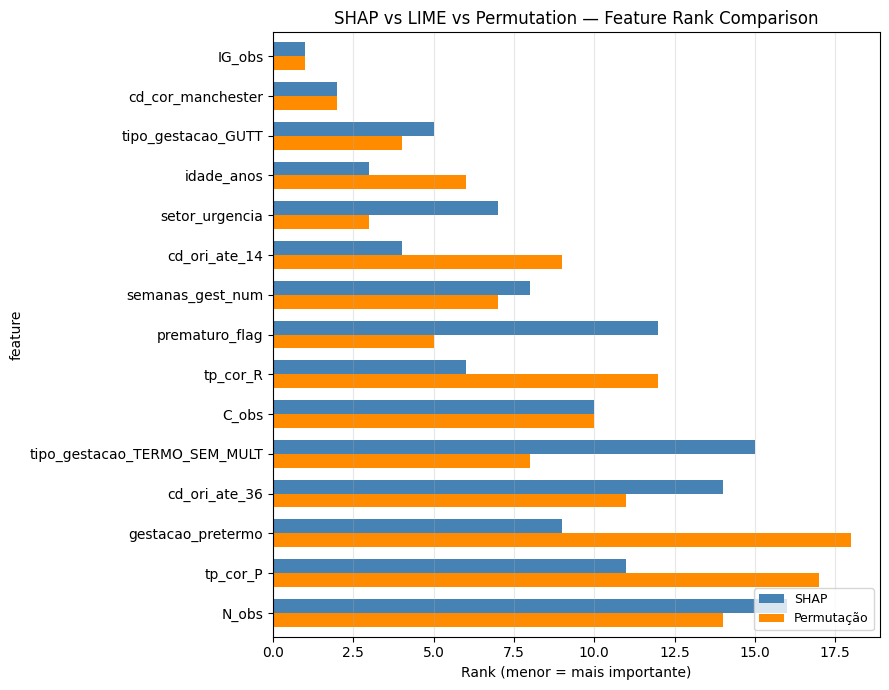

In [8]:
try:
    # Monta tabela comparativa de rankings das top-15 features por método
    _rank_rows = []

    # SHAP
    try:
        _shap_best_csv = OUT_DIR / f"shap_importancia_global_{_nome_perm_best}.csv"
        if _shap_best_csv.exists():
            _shap_rank = pd.read_csv(_shap_best_csv)
            _shap_rank = _shap_rank.reset_index().rename(columns={"index": "rank_shap"})
            _shap_rank["rank_shap"] += 1
            for _, row in _shap_rank.iterrows():
                _rank_rows.append({"feature": row["feature"],
                                    "metodo": "SHAP", "rank": int(row["rank_shap"]),
                                    "score": round(row["shap_mean"], 6)})
    except Exception:
        pass

    # LIME
    try:
        _lime_csv = OUT_DIR / "lime_importancia_global.csv"
        if _lime_csv.exists():
            _lime_rank = pd.read_csv(_lime_csv).reset_index()
            _lime_rank["rank_lime"] = _lime_rank.index + 1
            for _, row in _lime_rank.iterrows():
                _rank_rows.append({"feature": row["feature"],
                                    "metodo": "LIME", "rank": int(row["rank_lime"]),
                                    "score": round(row["lime_mean_abs_weight"], 6)})
    except Exception:
        pass

    # Permutation
    try:
        _perm_csv = OUT_DIR / "perm_importance_todos_modelos.csv"
        if _perm_csv.exists():
            _perm_rank = (
                pd.read_csv(_perm_csv)
                .query(f"modelo == '{_nome_perm_best}'")
                .sort_values("perm_mean", ascending=False)
                .reset_index(drop=True)
            )
            _perm_rank["rank_perm"] = _perm_rank.index + 1
            for _, row in _perm_rank.head(25).iterrows():
                _rank_rows.append({"feature": row["feature"],
                                    "metodo": "Permutação", "rank": int(row["rank_perm"]),
                                    "score": round(row["perm_mean"], 6)})
    except Exception:
        pass

    if _rank_rows:
        _df_rank = pd.DataFrame(_rank_rows)
        _pivot_rank = _df_rank.pivot_table(
            index="feature", columns="metodo", values="rank", aggfunc="first"
        )
        # Top 15 features presentes em pelo menos 2 dos 3 métodos
        _pivot_rank["presente_em"] = _pivot_rank.notna().sum(axis=1)
        _top_rank = (
            _pivot_rank[_pivot_rank["presente_em"] >= 2]
            .drop(columns="presente_em")
            .assign(rank_medio=lambda df: df.mean(axis=1, skipna=True))
            .sort_values("rank_medio")
            .head(15)
            .drop(columns="rank_medio")
        )

        fig_rank, ax_rank = plt.subplots(figsize=(9, 7))
        _methods_avail = [c for c in ["SHAP", "LIME", "Permutação"] if c in _top_rank.columns]
        _top_rank[_methods_avail].plot(
            kind="barh", ax=ax_rank, width=0.7,
            color=["steelblue", "darkorange", "seagreen"][:len(_methods_avail)],
        )
        ax_rank.invert_yaxis()
        ax_rank.set_xlabel("Rank (menor = mais importante)")
        ax_rank.set_title(T["lime_comp_title"])
        ax_rank.legend(fontsize=9, loc="lower right")
        ax_rank.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.savefig(PLOT_DIR / "15_comparacao_shap_lime_perm.png", dpi=150, bbox_inches="tight")
        plt.show(); plt.close()
        print("  Gerado: 15_comparacao_shap_lime_perm.png")

        _df_rank.to_csv(OUT_DIR / "comparacao_rankings_xai.csv", index=False)
        print("\n  Tabela de rankings (top 15, presentes em ≥2 métodos):")
        print(_top_rank.to_string())

except Exception as _e_rank:
    print(f"[Comparação] Erro: {type(_e_rank).__name__}: {_e_rank}")

print(f"\n[03.4] Concluído. Outputs: {OUT_DIR}")